# Bristol Rental Intelligence

## Notebook 2: Monthly rent forecasting

**Objective:** Build and evaluate a model that forecasts Bristol's average monthly private rent.

**Target variable:** Average monthly rental price (£).

**Validation approach:** Reserve the most recent 12 months as unseen test data. Train the model only on earlier data, then compare its predictions with the actual rents.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the project root from this notebook's folder.
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent

# Load the cleaned dataset created in Notebook 1.
CLEAN_DATA_FILE = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "bristol_rental_prices_clean.csv"
)

model_data = pd.read_csv(
    CLEAN_DATA_FILE,
    parse_dates=["Time period"]
)

# Ensure records are in time order.
model_data = (
    model_data
    .sort_values("Time period")
    .reset_index(drop=True)
)

print(f"Dataset shape: {model_data.shape}")
print(
    "Date range:",
    model_data["Time period"].min().strftime("%B %Y"),
    "to",
    model_data["Time period"].max().strftime("%B %Y")
)

model_data.head()

Dataset shape: (140, 11)
Date range: January 2015 to August 2026


,Time period,Rental price,Annual change,Rental price one bed,Rental price two bed,Rental price three bed,Rental price four or more bed,Rental price detached,Rental price semidetached,Rental price terraced,Rental price flat maisonette
0,2015-01-01,1041,NaN,670,864,959,1441,1175,1146,1106,838
1,2015-02-01,1045,NaN,673,868,963,1447,1180,1151,1111,842
2,2015-03-01,1050,NaN,676,872,968,1454,1185,1156,1116,846
3,2015-04-01,1053,NaN,679,875,971,1457,1189,1160,1120,848
4,2015-05-01,1058,NaN,681,878,975,1463,1194,1164,1124,852


In [2]:
# Reserve the final 12 months for testing.
TEST_MONTHS = 12

train_data = model_data.iloc[:-TEST_MONTHS].copy()
test_data = model_data.iloc[-TEST_MONTHS:].copy()

print(f"Training records: {len(train_data)}")
print(
    "Training period:",
    train_data["Time period"].min().strftime("%B %Y"),
    "to",
    train_data["Time period"].max().strftime("%B %Y")
)

print(f"\nTest records: {len(test_data)}")
print(
    "Test period:",
    test_data["Time period"].min().strftime("%B %Y"),
    "to",
    test_data["Time period"].max().strftime("%B %Y")
)

# Display the withheld test data.
test_data[
    ["Time period", "Rental price"]
]

Training records: 128
Training period: January 2015 to August 2025

Test records: 12
Test period: September 2025 to August 2026


,Time period,Rental price
128,2025-09-01,1791
129,2025-10-01,1824
130,2025-11-01,1858
131,2025-12-01,1889
132,2026-01-01,1893
133,2026-02-01,1891
134,2026-03-01,1888
135,2026-04-01,1885
136,2026-05-01,1883
137,2026-06-01,1883


In [3]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# The naive forecast repeats the last rent value observed in training.
last_training_rent = train_data["Rental price"].iloc[-1]

test_data = test_data.copy()
test_data["Naive forecast"] = last_training_rent

# Calculate forecast errors.
naive_mae = mean_absolute_error(
    test_data["Rental price"],
    test_data["Naive forecast"]
)

naive_rmse = (
    mean_squared_error(
        test_data["Rental price"],
        test_data["Naive forecast"]
    )
    ** 0.5
)

naive_mape = (
    (
        abs(
            test_data["Rental price"]
            - test_data["Naive forecast"]
        )
        / test_data["Rental price"]
    ).mean()
    * 100
)

# Present the results clearly.
naive_metrics = pd.DataFrame({
    "Metric": [
        "Last observed training rent",
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "Mean Absolute Percentage Error (MAPE)"
    ],
    "Value": [
        f"£{last_training_rent:,.0f}",
        f"£{naive_mae:,.2f}",
        f"£{naive_rmse:,.2f}",
        f"{naive_mape:.2f}%"
    ]
})

naive_metrics

,Metric,Value
0,Last observed training rent,"£1,778"
1,Mean Absolute Error (MAE),£92.67
2,Root Mean Squared Error (RMSE),£97.48
3,Mean Absolute Percentage Error (MAPE),4.93%


In [4]:
from sklearn.linear_model import LinearRegression

def create_time_features(data, reference_date):
    """
    Create numerical features from monthly dates.

    reference_date:
        The first date in the full dataset. It keeps the time index
        consistent between training data and test data.
    """
    features = pd.DataFrame(index=data.index)

    # Number of months since the beginning of the dataset.
    features["months_since_start"] = (
        (data["Time period"].dt.year - reference_date.year) * 12
        + (
            data["Time period"].dt.month
            - reference_date.month
        )
    )

    # Convert month number into cyclical seasonal features.
    # December and January should be treated as close together.
    features["month_sin"] = np.sin(
        2 * np.pi * data["Time period"].dt.month / 12
    )

    features["month_cos"] = np.cos(
        2 * np.pi * data["Time period"].dt.month / 12
    )

    return features


# Use the earliest month as the shared time reference.
reference_date = model_data["Time period"].min()

# Create features separately for training and test data.
X_train = create_time_features(train_data, reference_date)
X_test = create_time_features(test_data, reference_date)

# The target we want to predict.
y_train = train_data["Rental price"]
y_test = test_data["Rental price"]

print("Training features:")
display(X_train.head())

print("\nTest features:")
display(X_test.head())

Training features:


,months_since_start,month_sin,month_cos
0,0,0.500000,8.660254e-01
1,1,0.866025,5.000000e-01
2,2,1.000000,6.123234e-17
3,3,0.866025,-5.000000e-01
4,4,0.500000,-8.660254e-01



Test features:


,months_since_start,month_sin,month_cos
128,128,-1.000000e+00,-1.836970e-16
129,129,-8.660254e-01,5.000000e-01
130,130,-5.000000e-01,8.660254e-01
131,131,-2.449294e-16,1.000000e+00
132,132,5.000000e-01,8.660254e-01


In [5]:
# Create and train the model using training data only.
trend_model = LinearRegression()

trend_model.fit(
    X_train,
    y_train
)

# Predict rents for the 12 unseen test months.
test_data = test_data.copy()

test_data["Trend and seasonality forecast"] = (
    trend_model.predict(X_test)
)

# Calculate model errors.
trend_mae = mean_absolute_error(
    y_test,
    test_data["Trend and seasonality forecast"]
)

trend_rmse = (
    mean_squared_error(
        y_test,
        test_data["Trend and seasonality forecast"]
    )
    ** 0.5
)

trend_mape = (
    (
        abs(
            y_test
            - test_data["Trend and seasonality forecast"]
        )
        / y_test
    ).mean()
    * 100
)

# Compare the new model with the naive benchmark.
model_comparison = pd.DataFrame({
    "Model": [
        "Naive baseline",
        "Trend and seasonality regression"
    ],
    "MAE (£)": [
        round(naive_mae, 2),
        round(trend_mae, 2)
    ],
    "RMSE (£)": [
        round(naive_rmse, 2),
        round(trend_rmse, 2)
    ],
    "MAPE (%)": [
        round(naive_mape, 2),
        round(trend_mape, 2)
    ]
})

print("Model comparison:")
display(model_comparison)

print("\nTest-period predictions:")
display(
    test_data[
        [
            "Time period",
            "Rental price",
            "Naive forecast",
            "Trend and seasonality forecast"
        ]
    ]
)

Model comparison:


,Model,MAE (£),RMSE (£),MAPE (%)
0,Naive baseline,92.67,97.48,4.93
1,Trend and seasonality regression,68.66,72.02,3.66



Test-period predictions:


,Time period,Rental price,Naive forecast,Trend and seasonality forecast
128,2025-09-01,1791,1778,1766.293837
129,2025-10-01,1824,1778,1772.260805
130,2025-11-01,1858,1778,1779.044717
131,2025-12-01,1889,1778,1786.417620
132,2026-01-01,1893,1778,1793.993739
133,2026-02-01,1891,1778,1801.332848
134,2026-03-01,1888,1778,1808.058229
135,2026-04-01,1885,1778,1813.957609
136,2026-05-01,1883,1778,1819.040044
137,2026-06-01,1883,1778,1823.533488


In [7]:
from matplotlib.ticker import FuncFormatter

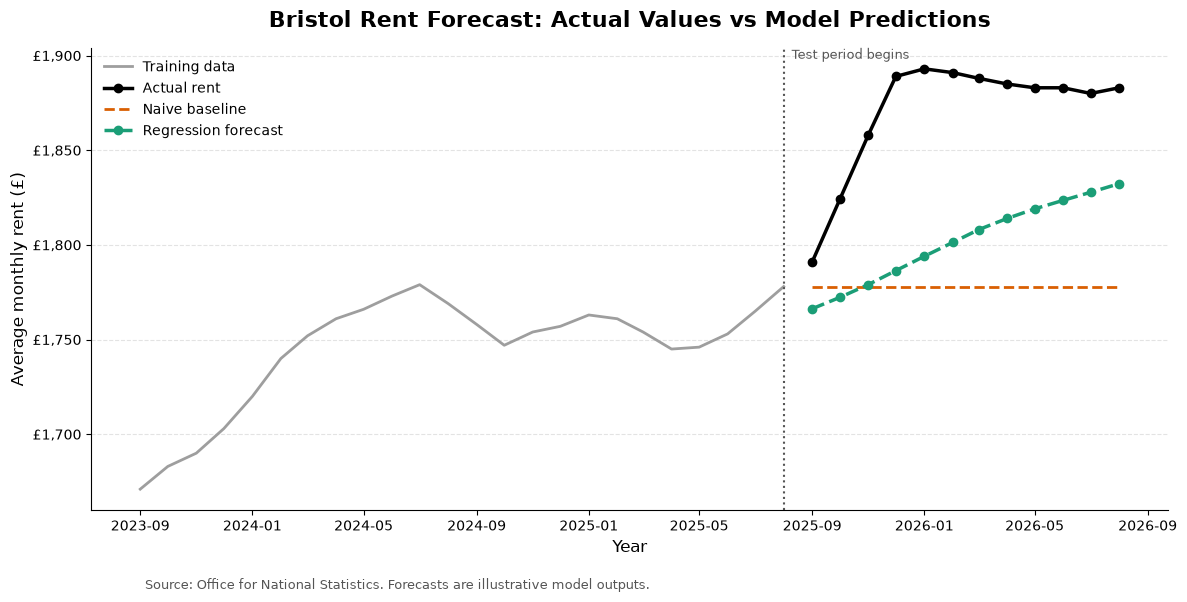

Chart saved to: /Users/Chibaba/Documents/Projects/bristol-rental-intelligence/reports/figures/bristol_forecast_evaluation.png


In [8]:
# Create a folder for model-evaluation charts.
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Show the final two years of training data for context.
recent_training_data = train_data.tail(24)

fig, ax = plt.subplots(figsize=(12, 6))

# Historical training data.
ax.plot(
    recent_training_data["Time period"],
    recent_training_data["Rental price"],
    color="#9e9e9e",
    linewidth=2,
    label="Training data"
)

# Actual rent values in the withheld test period.
ax.plot(
    test_data["Time period"],
    test_data["Rental price"],
    color="#000000",
    linewidth=2.5,
    marker="o",
    label="Actual rent"
)

# Naive baseline forecast.
ax.plot(
    test_data["Time period"],
    test_data["Naive forecast"],
    color="#d95f02",
    linewidth=2,
    linestyle="--",
    label="Naive baseline"
)

# Trend-and-seasonality forecast.
ax.plot(
    test_data["Time period"],
    test_data["Trend and seasonality forecast"],
    color="#1b9e77",
    linewidth=2.5,
    linestyle="--",
    marker="o",
    label="Regression forecast"
)

# Mark the boundary between training and test data.
ax.axvline(
    train_data["Time period"].iloc[-1],
    color="#555555",
    linestyle=":",
    linewidth=1.5
)

ax.text(
    train_data["Time period"].iloc[-1],
    ax.get_ylim()[1],
    "  Test period begins",
    va="top",
    fontsize=9,
    color="#555555"
)

# Format the chart.
ax.set_title(
    "Bristol Rent Forecast: Actual Values vs Model Predictions",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Average monthly rent (£)", fontsize=12)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"£{value:,.0f}")
)

ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.125,
    0.01,
    "Source: Office for National Statistics. Forecasts are illustrative model outputs.",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

forecast_chart_path = (
    FIGURE_DIR / "bristol_forecast_evaluation.png"
)

fig.savefig(
    forecast_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved to: {forecast_chart_path}")

In [9]:
# Train the final model on all available historical data.
X_full = create_time_features(
    model_data,
    reference_date
)

y_full = model_data["Rental price"]

final_forecast_model = LinearRegression()
final_forecast_model.fit(X_full, y_full)

# Create the next 12 monthly dates after the latest observed month.
latest_observed_date = model_data["Time period"].max()

future_dates = pd.date_range(
    start=latest_observed_date + pd.DateOffset(months=1),
    periods=12,
    freq="MS"
)

future_data = pd.DataFrame({
    "Time period": future_dates
})

# Create features for the future dates and generate predictions.
X_future = create_time_features(
    future_data,
    reference_date
)

future_data["Forecast rental price"] = (
    final_forecast_model.predict(X_future)
)

# Round predictions to whole pounds for presentation.
future_data["Forecast rental price"] = (
    future_data["Forecast rental price"].round(0).astype(int)
)

print(
    "Forecast period:",
    future_data["Time period"].min().strftime("%B %Y"),
    "to",
    future_data["Time period"].max().strftime("%B %Y")
)

print(
    "Forecast rent in final month:",
    f"£{future_data['Forecast rental price'].iloc[-1]:,.0f}"
)

future_data

Forecast period: September 2026 to August 2027
Forecast rent in final month: £1,926


,Time period,Forecast rental price
0,2026-09-01,1858
1,2026-10-01,1865
2,2026-11-01,1874
3,2026-12-01,1883
4,2027-01-01,1891
5,2027-02-01,1899
6,2027-03-01,1905
7,2027-04-01,1910
8,2027-05-01,1914
9,2027-06-01,1917


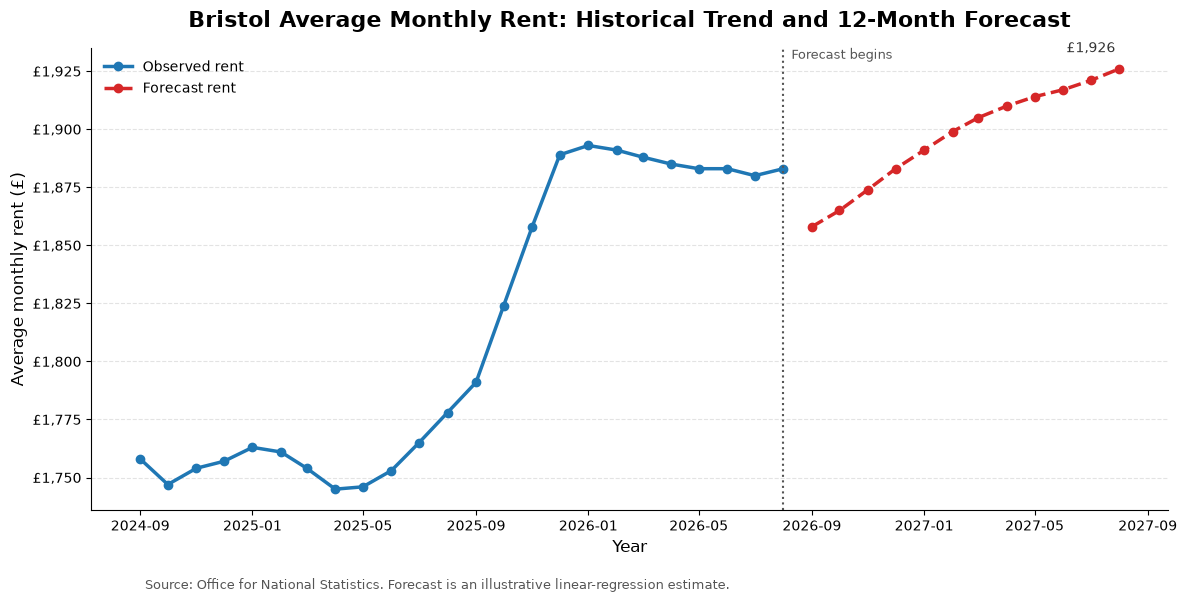

Forecast CSV saved to: /Users/Chibaba/Documents/Projects/bristol-rental-intelligence/data/processed/bristol_rent_forecast_sep2026_aug2027.csv
Forecast chart saved to: /Users/Chibaba/Documents/Projects/bristol-rental-intelligence/reports/figures/bristol_12_month_rent_forecast.png


In [10]:
# Save the forecast table as a reusable project output.
FORECAST_FILE = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "bristol_rent_forecast_sep2026_aug2027.csv"
)

future_data.to_csv(
    FORECAST_FILE,
    index=False
)

# Use the most recent 24 actual months for chart context.
recent_actual_data = model_data.tail(24)

fig, ax = plt.subplots(figsize=(12, 6))

# Recent actual rents.
ax.plot(
    recent_actual_data["Time period"],
    recent_actual_data["Rental price"],
    color="#1f77b4",
    linewidth=2.5,
    marker="o",
    label="Observed rent"
)

# Forecast rent values.
ax.plot(
    future_data["Time period"],
    future_data["Forecast rental price"],
    color="#d62728",
    linewidth=2.5,
    linestyle="--",
    marker="o",
    label="Forecast rent"
)

# Mark the point where historical data ends and forecasting begins.
ax.axvline(
    latest_observed_date,
    color="#555555",
    linestyle=":",
    linewidth=1.5
)

ax.text(
    latest_observed_date,
    ax.get_ylim()[1],
    "  Forecast begins",
    va="top",
    fontsize=9,
    color="#555555"
)

# Label the final forecast value.
final_forecast_date = future_data["Time period"].iloc[-1]
final_forecast_value = future_data["Forecast rental price"].iloc[-1]

ax.annotate(
    f"£{final_forecast_value:,.0f}",
    xy=(final_forecast_date, final_forecast_value),
    xytext=(-38, 12),
    textcoords="offset points",
    fontsize=10,
    color="#333333"
)

# Format the chart.
ax.set_title(
    "Bristol Average Monthly Rent: Historical Trend and 12-Month Forecast",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Average monthly rent (£)", fontsize=12)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"£{value:,.0f}")
)

ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.125,
    0.01,
    "Source: Office for National Statistics. Forecast is an illustrative linear-regression estimate.",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

future_forecast_chart_path = (
    FIGURE_DIR / "bristol_12_month_rent_forecast.png"
)

fig.savefig(
    future_forecast_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Forecast CSV saved to: {FORECAST_FILE}")
print(f"Forecast chart saved to: {future_forecast_chart_path}")

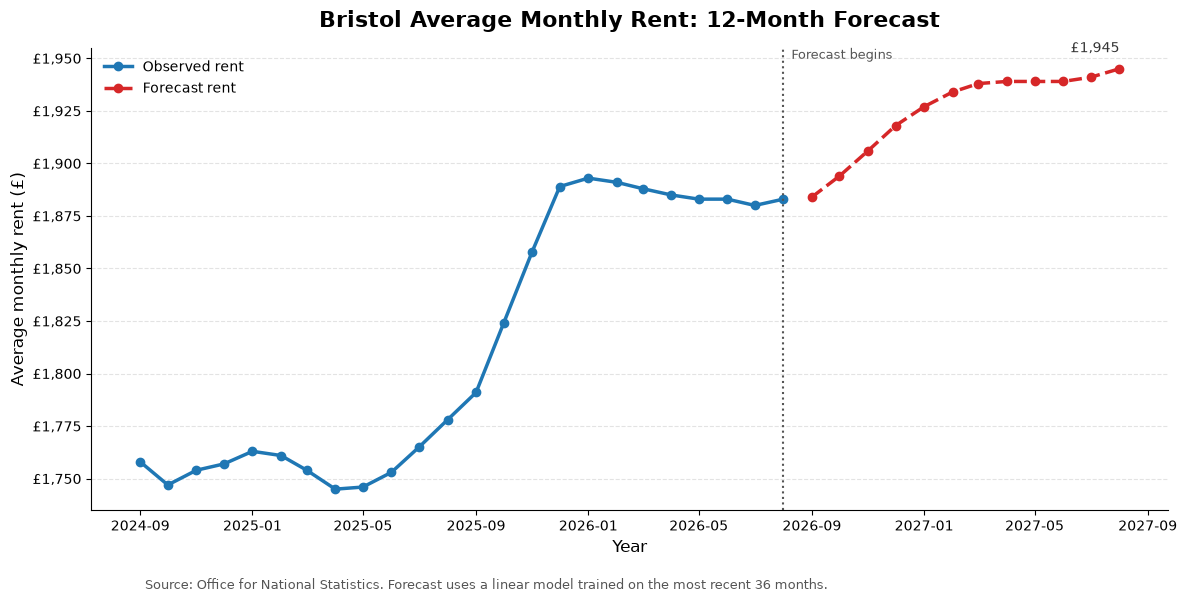

Final forecast chart saved to: /Users/Chibaba/Documents/Projects/bristol-rental-intelligence/reports/figures/bristol_12_month_rent_forecast.png


In [13]:
# Keep the latest 24 months of real, observed rent values.
recent_actual_data = model_data.tail(24)

# Create an empty chart.
fig, ax = plt.subplots(figsize=(12, 6))

# Draw the blue line: real ONS rental-price data.
ax.plot(
    recent_actual_data["Time period"],
    recent_actual_data["Rental price"],
    color="#1f77b4",
    linewidth=2.5,
    marker="o",
    label="Observed rent"
)

# Draw the red dashed line: our 12-month forecast.
ax.plot(
    future_data["Time period"],
    future_data["Forecast rental price"],
    color="#d62728",
    linewidth=2.5,
    linestyle="--",
    marker="o",
    label="Forecast rent"
)

# Identify the last month with real data.
latest_observed_date = model_data["Time period"].max()

# Add a dotted vertical line where the forecast starts.
ax.axvline(
    latest_observed_date,
    color="#555555",
    linestyle=":",
    linewidth=1.5
)

# Add a small label beside the forecast boundary.
ax.text(
    latest_observed_date,
    ax.get_ylim()[1],
    "  Forecast begins",
    va="top",
    fontsize=9,
    color="#555555"
)

# Get the final prediction: August 2027.
final_forecast_date = future_data["Time period"].iloc[-1]
final_forecast_value = future_data["Forecast rental price"].iloc[-1]

# Label the final prediction on the chart.
ax.annotate(
    f"£{final_forecast_value:,.0f}",
    xy=(final_forecast_date, final_forecast_value),
    xytext=(-35, 12),
    textcoords="offset points",
    fontsize=10,
    color="#333333"
)

# Add the chart title and axis labels.
ax.set_title(
    "Bristol Average Monthly Rent: 12-Month Forecast",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Average monthly rent (£)", fontsize=12)

# Format y-axis numbers as British pounds.
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"£{value:,.0f}")
)

# Improve readability.
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add the source and model note below the chart.
fig.text(
    0.125,
    0.01,
    (
        "Source: Office for National Statistics. "
        "Forecast uses a linear model trained on the most recent 36 months."
    ),
    fontsize=9,
    color="#555555"
)

# Prevent labels and source text from being cut off.
plt.tight_layout(rect=[0, 0.04, 1, 1])

# Choose where the image will be saved.
future_forecast_chart_path = (
    FIGURE_DIR / "bristol_12_month_rent_forecast.png"
)

# Save a high-quality image.
fig.savefig(
    future_forecast_chart_path,
    dpi=300,
    bbox_inches="tight"
)

# Display the chart in the notebook.
plt.show()

# Confirm the saved-image location.
print(f"Final forecast chart saved to: {future_forecast_chart_path}")

In [11]:
RECENT_TRAINING_MONTHS = 36

recent_train_data = train_data.tail(
    RECENT_TRAINING_MONTHS
).copy()

X_recent_train = create_time_features(
    recent_train_data,
    reference_date
)

y_recent_train = recent_train_data["Rental price"]

recent_trend_model = LinearRegression()

recent_trend_model.fit(
    X_recent_train,
    y_recent_train
)

test_data["Recent trend forecast"] = (
    recent_trend_model.predict(X_test)
)

recent_trend_mae = mean_absolute_error(
    y_test,
    test_data["Recent trend forecast"]
)

recent_trend_rmse = (
    mean_squared_error(
        y_test,
        test_data["Recent trend forecast"]
    ) ** 0.5
)

recent_trend_mape = (
    (
        abs(
            y_test - test_data["Recent trend forecast"]
        ) / y_test
    ).mean() * 100
)

all_model_comparison = pd.DataFrame({
    "Model": [
        "Naive baseline",
        "Full-history trend and seasonality",
        "Recent 36-month trend and seasonality"
    ],
    "MAE (£)": [
        round(naive_mae, 2),
        round(trend_mae, 2),
        round(recent_trend_mae, 2)
    ],
    "RMSE (£)": [
        round(naive_rmse, 2),
        round(trend_rmse, 2),
        round(recent_trend_rmse, 2)
    ],
    "MAPE (%)": [
        round(naive_mape, 2),
        round(trend_mape, 2),
        round(recent_trend_mape, 2)
    ]
})

all_model_comparison

,Model,MAE (£),RMSE (£),MAPE (%)
0,Naive baseline,92.67,97.48,4.93
1,Full-history trend and seasonality,68.66,72.02,3.66
2,Recent 36-month trend and seasonality,24.52,31.07,1.31


In [12]:
# Retrain the selected model using the most recent 36 months
# of all available data, now including data through August 2026.
final_recent_training_data = model_data.tail(
    RECENT_TRAINING_MONTHS
).copy()

X_final_recent = create_time_features(
    final_recent_training_data,
    reference_date
)

y_final_recent = final_recent_training_data["Rental price"]

final_recent_model = LinearRegression()

final_recent_model.fit(
    X_final_recent,
    y_final_recent
)

# Create the September 2026 to August 2027 forecast dates.
future_dates = pd.date_range(
    start=model_data["Time period"].max() + pd.DateOffset(months=1),
    periods=12,
    freq="MS"
)

future_data = pd.DataFrame({
    "Time period": future_dates
})

X_future = create_time_features(
    future_data,
    reference_date
)

future_data["Forecast rental price"] = (
    final_recent_model.predict(X_future)
    .round(0)
    .astype(int)
)

# Overwrite the preliminary forecast CSV with the selected model's output.
future_data.to_csv(
    FORECAST_FILE,
    index=False
)

# Print a concise forecast summary.
forecast_start = future_data["Forecast rental price"].iloc[0]
forecast_end = future_data["Forecast rental price"].iloc[-1]

print(
    "Selected model: Recent 36-month trend and seasonality"
)

print(
    "Forecast period:",
    future_data["Time period"].min().strftime("%B %Y"),
    "to",
    future_data["Time period"].max().strftime("%B %Y")
)

print(f"First forecast: £{forecast_start:,.0f}")
print(f"Final forecast: £{forecast_end:,.0f}")
print(f"Forecast change: £{forecast_end - forecast_start:,.0f}")

future_data

Selected model: Recent 36-month trend and seasonality
Forecast period: September 2026 to August 2027
First forecast: £1,884
Final forecast: £1,945
Forecast change: £61


,Time period,Forecast rental price
0,2026-09-01,1884
1,2026-10-01,1894
2,2026-11-01,1906
3,2026-12-01,1918
4,2027-01-01,1927
5,2027-02-01,1934
6,2027-03-01,1938
7,2027-04-01,1939
8,2027-05-01,1939
9,2027-06-01,1939
